# 3. Resultados

Este notebook responde la pregunta del proyecto: ¿cómo reparto el presupuesto del próximo trimestre?

In [1]:
import json

from mmm import plots
from mmm.data import CHANNEL_LABELS
from mmm.export import simulate_plan

results = json.loads((plots.ROOT / "site" / "data" / "resultados.json").read_text(encoding="utf-8"))

## Cuánto aporta cada canal

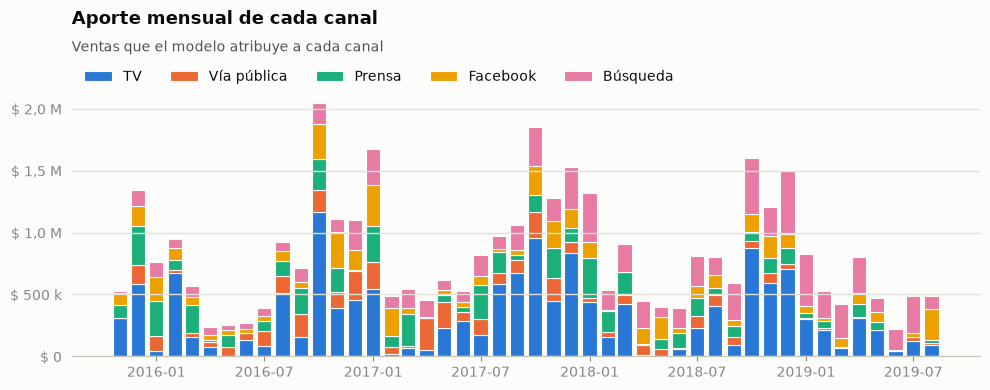

In [2]:
plots.plot_contributions(results);

## Retorno por canal

A la derecha de la línea en 1, el canal recupera lo invertido.

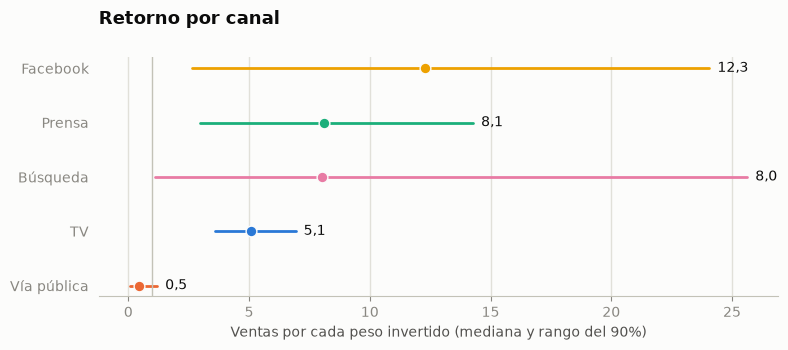

In [3]:
plots.plot_roi(results);

## Curvas de saturación

Cuando la curva se aplana, poner más plata en ese canal casi no suma. El punto marca el plan actual.

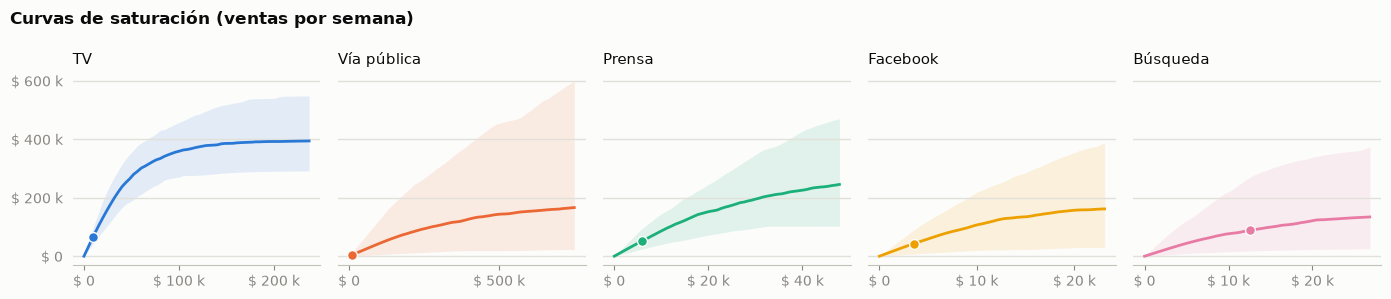

In [4]:
plots.plot_saturation(results);

## Reparto óptimo

El algoritmo SLSQP de scipy busca el reparto con más ventas de medios en el simulador, con el mismo total semanal que el plan actual.

In [5]:
import pandas as pd

plans = pd.DataFrame(results["plans"]).rename(index=CHANNEL_LABELS).round(0)
plans["cambio"] = plans["optimal"] - plans["current"]
plans

,current,optimal,cambio
TV,9474.0,6326.0,-3148.0
Vía pública,9649.0,0.0,-9649.0
Prensa,5938.0,13753.0,7815.0
Facebook,3510.0,12195.0,8685.0
Búsqueda,12542.0,8838.0,-3704.0


In [6]:
for name in ("current", "optimal"):
    media = simulate_plan(results, results["plans"][name])["media"]
    print(name, {k: round(v) for k, v in media.items()})
print(f"Mejora: {results['headline']['media_uplift_pct']:.1f}%")

current {'median': 3486914, 'p05': 2126288, 'p95': 5882173}
optimal {'median': 4706141, 'p05': 2930330, 'p95': 7139474}
Mejora: 35.0%
